<a href="https://colab.research.google.com/github/Ronniee7/NASA_CMAPSS_RUL_Engine_Degradation/blob/main/NASA_CMAPSS_RUL_Engine_degradation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# NASA C-MAPSS Turbofan Engine — Remaining Useful Life (RUL) Prediction
### An end-to-end, research-oriented predictive-maintenance notebook

**Author:** Asiimwe Ronald  
**Task:** Estimate how many operating cycles remain before an engine reaches its end of useful life.  
**Approach:** Exploratory data analysis → leakage-safe preprocessing → classical baseline → temporal CNN → official test evaluation → robustness analysis.

> **Research note:** No model is guaranteed to be the best before evaluation. This notebook compares models using the same engine-level validation split and reports results transparently. Run the notebook from top to bottom.

### What makes this notebook careful?
- Splits **engines**, not individual rows, to reduce train/validation leakage.
- Fits preprocessing only on training engines.
- Uses a capped RUL target, a common C-MAPSS modelling choice.
- Uses the official test RUL file for final test-engine evaluation.
- Reports MAE, RMSE, the NASA asymmetric score, plots, and a simple sensor-noise stress test.
- Keeps the test set out of model selection; use validation results to choose a model.

## 1. Setup

This notebook is designed for Google Colab. A GPU is helpful for the CNN but is not required.

**Dataset:** the classic C-MAPSS FD001–FD004 benchmark contains 21 sensor channels, three operating settings, and engine/cycle identifiers. FD001 is the recommended first run; FD002–FD004 are more challenging because they include multiple operating conditions and/or fault modes.

NASA dataset information: [NASA Prognostics Center of Excellence repository](https://www.nasa.gov/intelligent-systems-division/discovery-and-systems-health/pcoe/pcoe-data-set-repository/).

In [ ]:
# Install only what this notebook needs.
%pip -q install seaborn scikit-learn

In [ ]:
import os
import random
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)
print("PyTorch:", torch.__version__)

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams["figure.figsize"] = (11, 5)
plt.rcParams["figure.dpi"] = 120

Device: cuda
PyTorch: 2.11.0+cu130


## 2. Download and locate the data

The cell attempts to download the commonly mirrored original NASA C-MAPSS ZIP. If the download is blocked, use the upload fallback and upload the original ZIP or the extracted text files.

Expected files include `train_FD001.txt`, `test_FD001.txt`, and `RUL_FD001.txt` (and equivalents for FD002–FD004).

In [ ]:
DATA_DIR = Path("/content/cmapss_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

ZIP_URL = "https://phm-datasets.s3.amazonaws.com/NASA/6.+Turbofan+Engine+Degradation+Simulation+Data+Set.zip"
ZIP_PATH = DATA_DIR / "CMAPSSData.zip"

def find_dataset_root(root: Path):
    # Search recursively because ZIP files sometimes contain a nested directory.
    for p in root.rglob("train_FD001.txt"):
        return p.parent
    return None

dataset_root = find_dataset_root(DATA_DIR)

if dataset_root is None:
    try:
        print("Downloading the C-MAPSS archive...")
        urllib.request.urlretrieve(ZIP_URL, ZIP_PATH)
        with zipfile.ZipFile(ZIP_PATH, "r") as zf:
            zf.extractall(DATA_DIR)
        dataset_root = find_dataset_root(DATA_DIR)
    except Exception as e:
        print("Automatic download failed:", repr(e))

if dataset_root is None:
    print("\nUpload the original C-MAPSS ZIP or the extracted train/test/RUL text files.")
    try:
        from google.colab import files
        uploaded = files.upload()
        for name in uploaded:
            if name.lower().endswith(".zip"):
                with zipfile.ZipFile(name, "r") as zf:
                    zf.extractall(DATA_DIR)
            else:
                target = DATA_DIR / name
                target.write_bytes(uploaded[name])
        dataset_root = find_dataset_root(DATA_DIR)
        if dataset_root is None and (DATA_DIR / "train_FD001.txt").exists():
            dataset_root = DATA_DIR
    except ImportError:
        raise RuntimeError("Dataset not found. Place the original files in DATA_DIR and rerun.")

if dataset_root is None:
    raise FileNotFoundError(
        "Could not find train_FD001.txt. Check the archive contents or upload the original files."
    )

print("Dataset directory:", dataset_root)
print("Example files:", sorted(p.name for p in dataset_root.glob("*FD001*"))[:10])


Upload the original C-MAPSS ZIP or the extracted train/test/RUL text files.


Saving archive (3).zip to archive (3).zip
Dataset directory: /content/cmapss_data
Example files: ['RUL_FD001.txt', 'test_FD001.txt', 'train_FD001.txt']


## 3. Choose a subset and load the raw trajectories

Start with **FD001** to verify that everything runs. Later, change `SUBSET` to `FD002`, `FD003`, or `FD004`.

Each row contains: engine ID, cycle, three operating settings, and 21 sensor measurements.

In [ ]:
SUBSET = "FD001"   # Change to FD002, FD003, or FD004
RUL_CAP = 125      # Common capped-RUL formulation; also test alternatives in future work
WINDOW_SIZE = 30   # Number of recent cycles given to the temporal CNN
BATCH_SIZE = 128
EPOCHS = 60
LEARNING_RATE = 1e-3
PATIENCE = 10

assert SUBSET in {"FD001", "FD002", "FD003", "FD004"}

columns = (
    ["unit", "cycle", "setting_1", "setting_2", "setting_3"]
    + [f"sensor_{i}" for i in range(1, 22)]
)

def read_cmapss_file(path):
    # Whitespace-delimited files may contain trailing spaces.
    df = pd.read_csv(path, sep=r"\s+", header=None)
    df = df.dropna(axis=1, how="all")
    if df.shape[1] != len(columns):
        raise ValueError(f"Expected 26 columns in {path.name}, found {df.shape[1]}")
    df.columns = columns
    return df

train_path = dataset_root / f"train_{SUBSET}.txt"
test_path = dataset_root / f"test_{SUBSET}.txt"
rul_path = dataset_root / f"RUL_{SUBSET}.txt"

train_raw = read_cmapss_file(train_path)
test_raw = read_cmapss_file(test_path)
test_final_rul = pd.read_csv(rul_path, sep=r"\s+", header=None).iloc[:, 0].to_numpy()

print(f"Subset: {SUBSET}")
print("Train shape:", train_raw.shape, "| engines:", train_raw.unit.nunique())
print("Test shape: ", test_raw.shape,  "| engines:", test_raw.unit.nunique())
print("Official test RUL labels:", len(test_final_rul))
display(train_raw.head())

Subset: FD001
Train shape: (20631, 26) | engines: 100
Test shape:  (13096, 26) | engines: 100
Official test RUL labels: 100


,unit,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


## 4. Data quality checks

We verify missing values, duplicate records, cycle continuity, and the alignment between test engines and official RUL labels before modelling.

In [ ]:
print("Missing values in train:", int(train_raw.isna().sum().sum()))
print("Duplicate train rows:", int(train_raw.duplicated().sum()))
print("Missing values in test:", int(test_raw.isna().sum().sum()))
print("Duplicate test rows:", int(test_raw.duplicated().sum()))

train_lengths = train_raw.groupby("unit")["cycle"].agg(["min", "max", "count"])
test_lengths = test_raw.groupby("unit")["cycle"].agg(["min", "max", "count"])

print("\nTraining trajectory length summary:")
display(train_lengths["count"].describe().to_frame("cycles"))
print("\nTest trajectory length summary:")
display(test_lengths["count"].describe().to_frame("cycles"))

assert len(test_final_rul) == test_raw["unit"].nunique(), (
    "Official RUL count must match the number of test engines."
)
assert np.isfinite(train_raw.select_dtypes(include=np.number)).all().all()
assert np.isfinite(test_raw.select_dtypes(include=np.number)).all().all()

Missing values in train: 0
Duplicate train rows: 0
Missing values in test: 0
Duplicate test rows: 0

Training trajectory length summary:


,cycles
count,100.000000
mean,206.310000
std,46.342749
min,128.000000
25%,177.000000
50%,199.000000
75%,229.250000
max,362.000000



Test trajectory length summary:


,cycles
count,100.000000
mean,130.960000
std,53.593479
min,31.000000
25%,88.750000
50%,133.500000
75%,164.250000
max,303.000000


## 5. Exploratory data analysis — before training

These plots help us understand engine lifetimes, sensor behaviour, and which channels vary meaningfully. Constant or near-constant sensors may add noise rather than useful information.

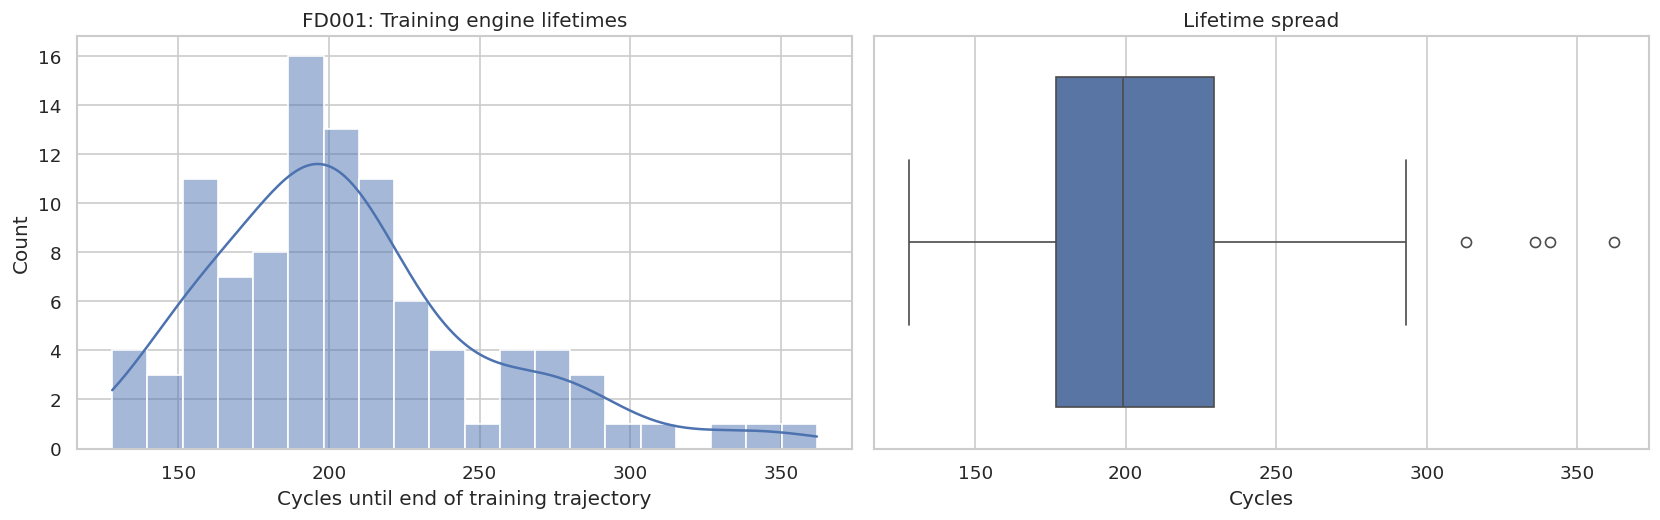

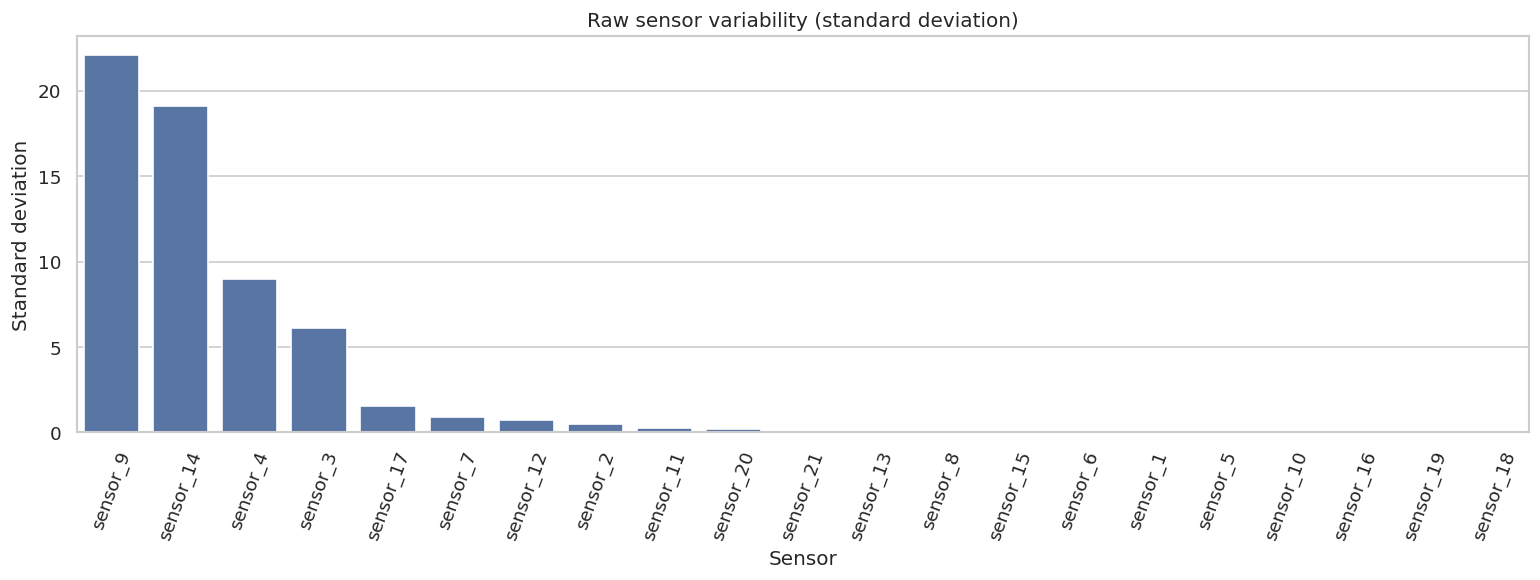

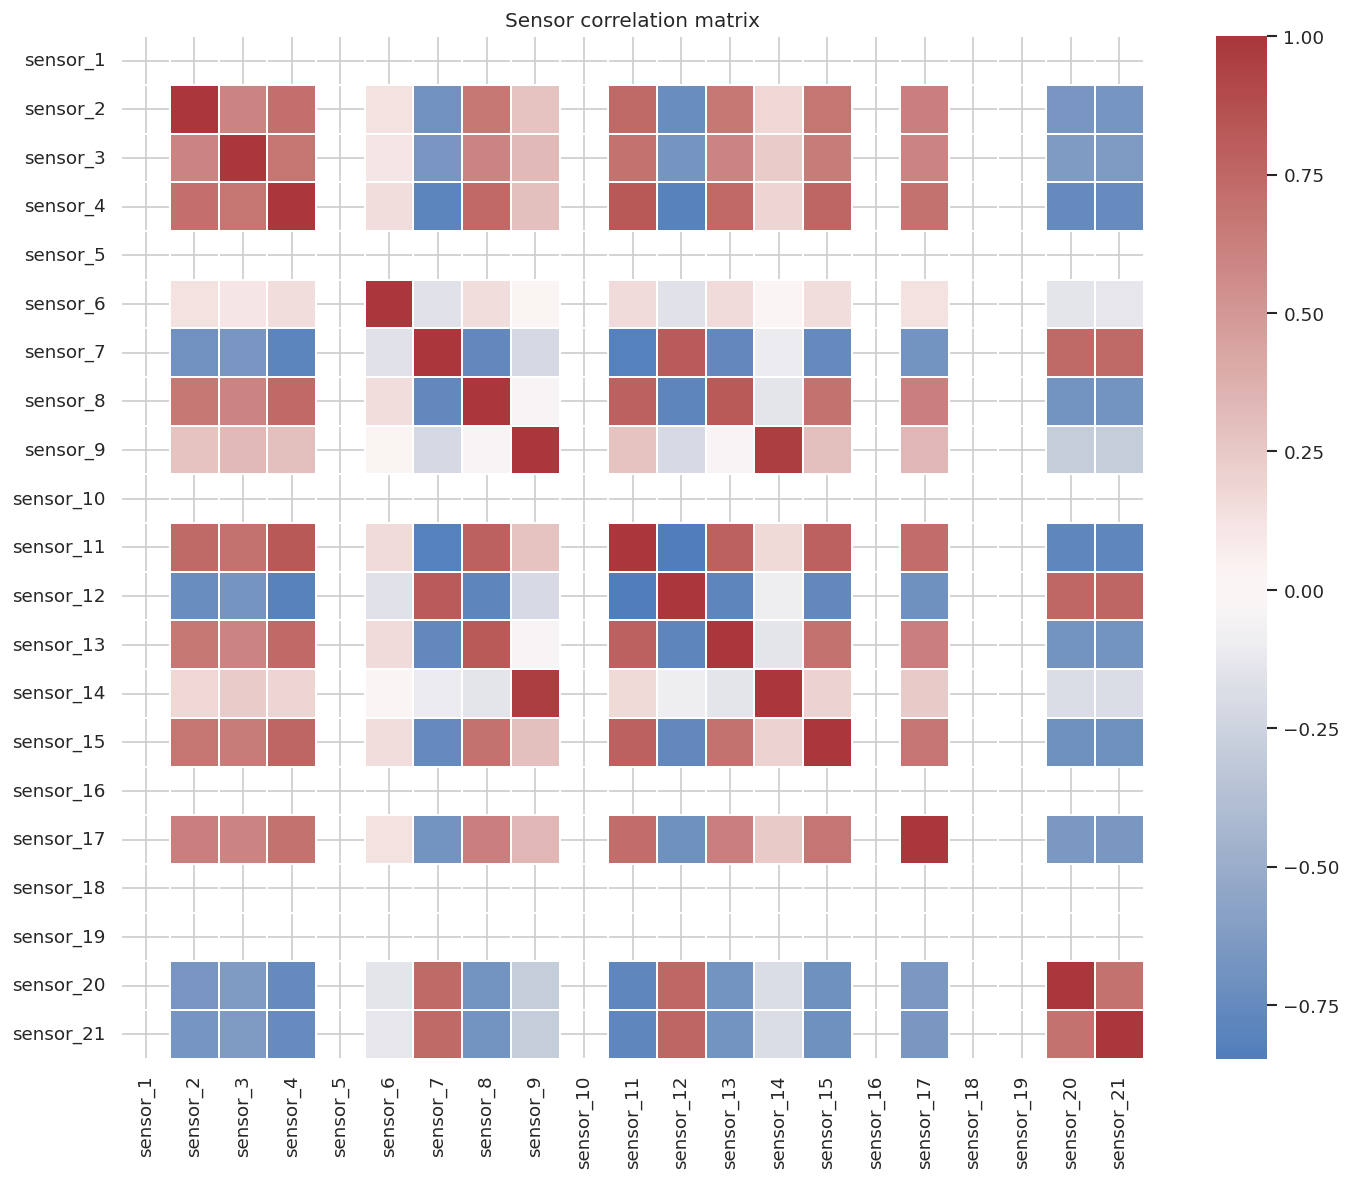

In [ ]:
# 5.1 Distribution of complete training-engine lifetimes
lifetimes = train_raw.groupby("unit")["cycle"].max()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
sns.histplot(lifetimes, bins=20, kde=True, ax=axes[0])
axes[0].set_title(f"{SUBSET}: Training engine lifetimes")
axes[0].set_xlabel("Cycles until end of training trajectory")
sns.boxplot(x=lifetimes, ax=axes[1])
axes[1].set_title("Lifetime spread")
axes[1].set_xlabel("Cycles")
plt.tight_layout()
plt.show()

# 5.2 Sensor variation across all training observations
sensor_cols = [c for c in columns if c.startswith("sensor_")]
sensor_std = train_raw[sensor_cols].std().sort_values(ascending=False)

plt.figure(figsize=(13, 5))
sns.barplot(x=sensor_std.index, y=sensor_std.values)
plt.xticks(rotation=70)
plt.title("Raw sensor variability (standard deviation)")
plt.ylabel("Standard deviation")
plt.xlabel("Sensor")
plt.tight_layout()
plt.show()

# 5.3 Correlation among sensors (useful for spotting redundancy)
plt.figure(figsize=(13, 10))
corr = train_raw[sensor_cols].corr()
sns.heatmap(corr, cmap="vlag", center=0, square=True, linewidths=0.1)
plt.title("Sensor correlation matrix")
plt.tight_layout()
plt.show()

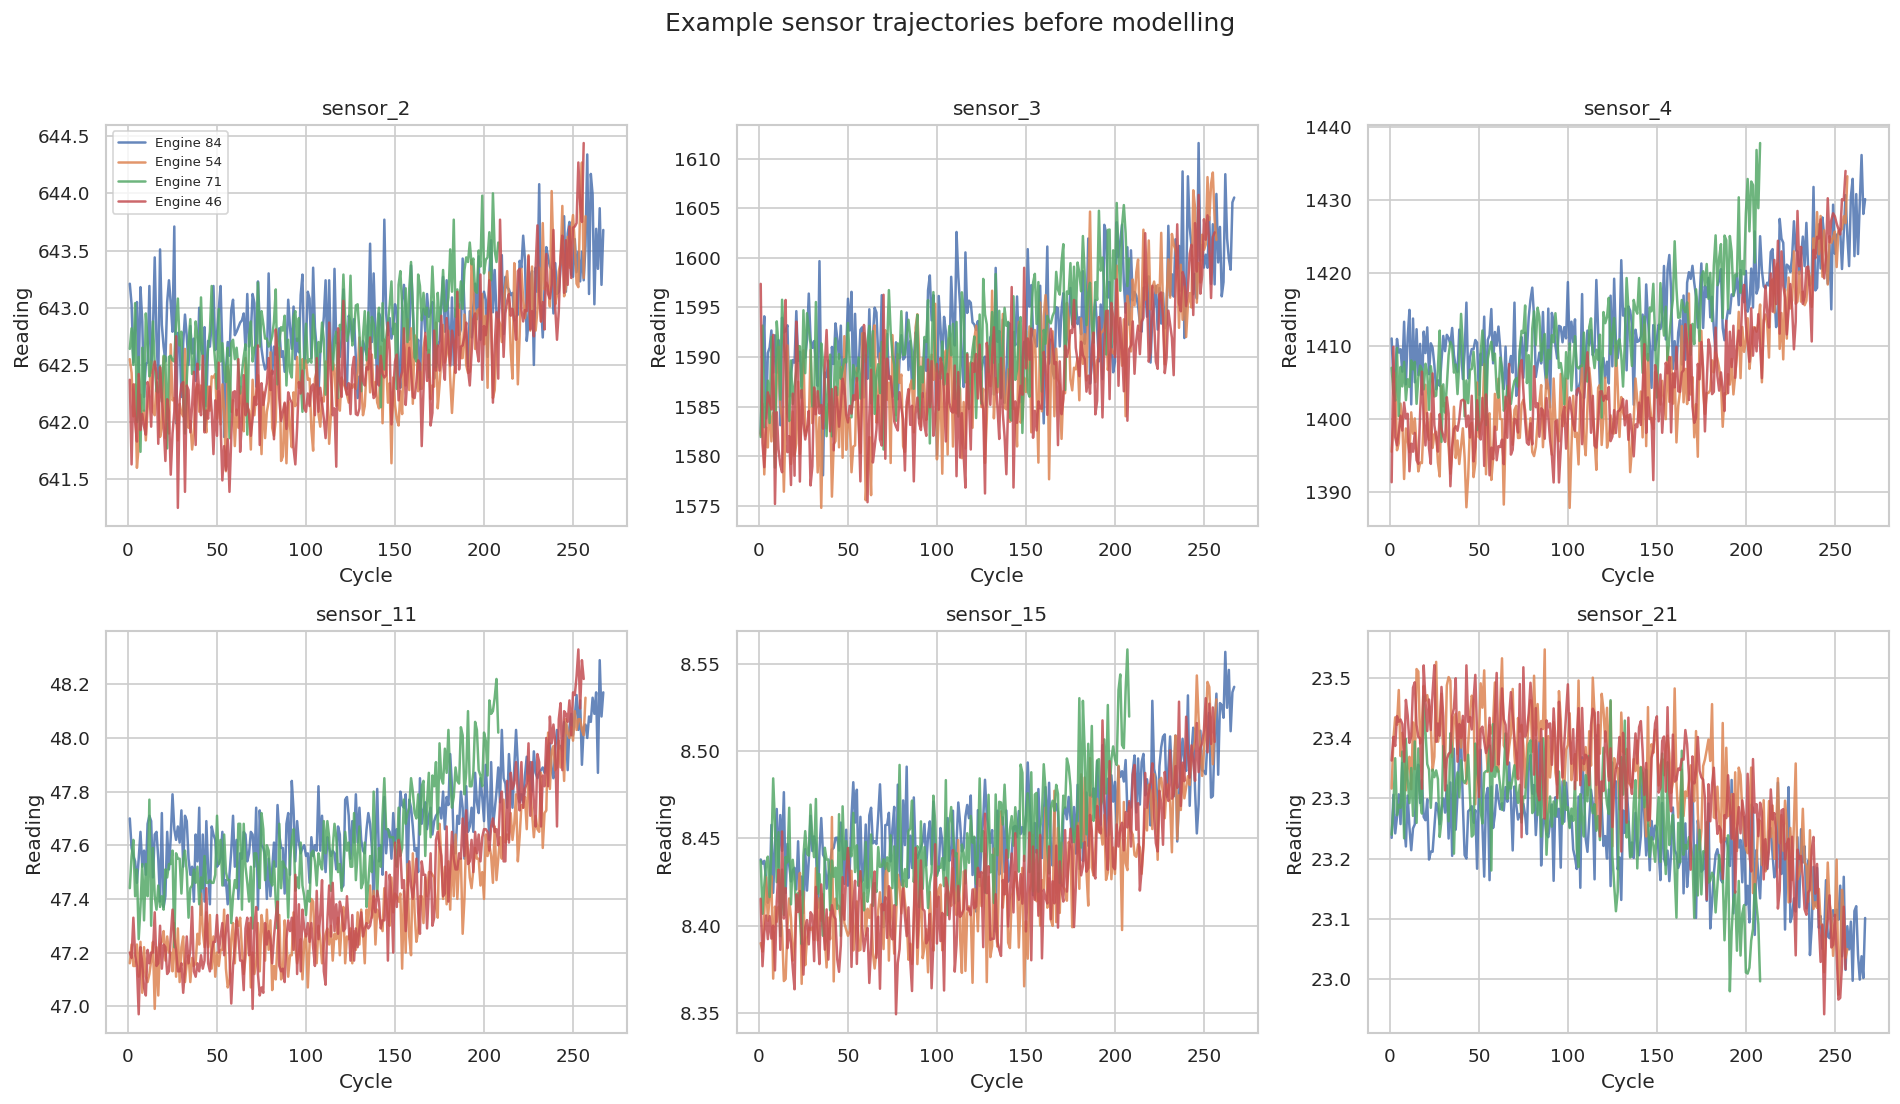

In [ ]:
# 5.4 Plot sensor trajectories for several example engines.
# The vertical axis is sensor value; the horizontal axis is operating cycle.
example_units = train_raw["unit"].drop_duplicates().sample(
    min(4, train_raw["unit"].nunique()), random_state=SEED
).tolist()

sensors_to_plot = ["sensor_2", "sensor_3", "sensor_4", "sensor_11", "sensor_15", "sensor_21"]
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, sensor in zip(axes.flat, sensors_to_plot):
    for unit_id in example_units:
        part = train_raw[train_raw.unit == unit_id]
        ax.plot(part.cycle, part[sensor], alpha=0.85, linewidth=1.5, label=f"Engine {unit_id}")
    ax.set_title(sensor)
    ax.set_xlabel("Cycle")
    ax.set_ylabel("Reading")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Example sensor trajectories before modelling", y=1.02, fontsize=15)
plt.tight_layout()
plt.show()

## 6. Create the Remaining Useful Life target

For a training engine, `RUL = final_cycle_for_that_engine - current_cycle`. We cap the target at `RUL_CAP`, so early-life observations do not dominate the regression problem.

For official test evaluation, each test engine stops before failure. Its final-cycle RUL is supplied in `RUL_FDxxx.txt`. The row-level RUL at cycle `t` is:

`official final RUL + (last observed test cycle - t)`

We will score the **last observed window for each test engine**, which is the usual operational prediction point.

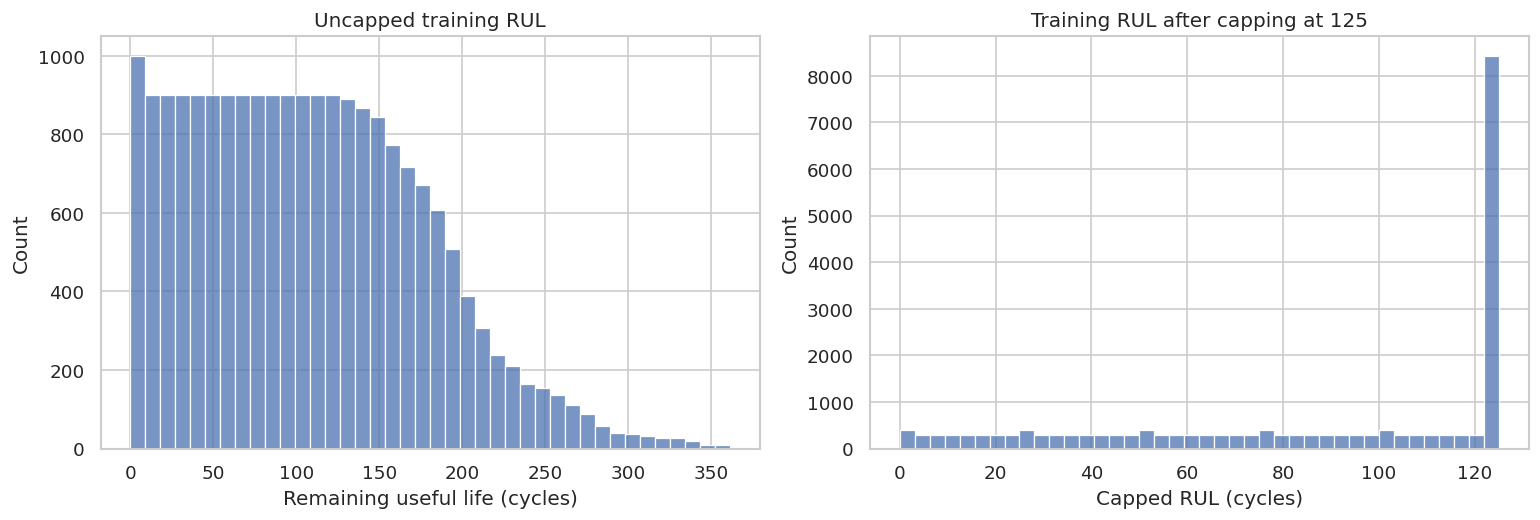

,unit,cycle,RUL_raw,RUL
0,1,1,191,125
1,1,2,190,125
2,1,3,189,125
3,1,4,188,125
4,1,5,187,125


In [ ]:
def add_train_rul(df):
    out = df.copy()
    final_cycles = out.groupby("unit")["cycle"].max()
    out["RUL_raw"] = out["unit"].map(final_cycles) - out["cycle"]
    out["RUL"] = out["RUL_raw"].clip(upper=RUL_CAP)
    return out

train_all = add_train_rul(train_raw)

# Map each test engine to its official final RUL; test unit IDs are ordered 1..N.
test_all = test_raw.copy()
test_units_sorted = sorted(test_all["unit"].unique())
official_rul_by_unit = dict(zip(test_units_sorted, test_final_rul))
last_test_cycle = test_all.groupby("unit")["cycle"].max().to_dict()
test_all["RUL_raw"] = test_all.apply(
    lambda row: official_rul_by_unit[row["unit"]] + last_test_cycle[row["unit"]] - row["cycle"],
    axis=1
)
test_all["RUL"] = test_all["RUL_raw"].clip(upper=RUL_CAP)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(train_all["RUL_raw"], bins=40, ax=ax[0])
ax[0].set_title("Uncapped training RUL")
ax[0].set_xlabel("Remaining useful life (cycles)")
sns.histplot(train_all["RUL"], bins=40, ax=ax[1])
ax[1].set_title(f"Training RUL after capping at {RUL_CAP}")
ax[1].set_xlabel("Capped RUL (cycles)")
plt.tight_layout()
plt.show()

display(train_all[["unit", "cycle", "RUL_raw", "RUL"]].head())

## 7. Leakage-safe engine-level validation split

A common mistake is randomly splitting rows. That can place cycles from the same engine in both training and validation, making results look unrealistically good.

Instead, we split by **engine ID** first. Every window from an engine belongs to only one split. The official test engines remain untouched until final evaluation.

In [ ]:
all_train_units = np.array(sorted(train_all["unit"].unique()))
fit_units, val_units = train_test_split(
    all_train_units, test_size=0.20, random_state=SEED
)

fit_df = train_all[train_all.unit.isin(fit_units)].copy()
val_df = train_all[train_all.unit.isin(val_units)].copy()

print(f"Training engines: {len(fit_units)}")
print(f"Validation engines: {len(val_units)}")
print("Engine overlap:", len(set(fit_units) & set(val_units)))
assert len(set(fit_units) & set(val_units)) == 0

Training engines: 80
Validation engines: 20
Engine overlap: 0


## 8. Preprocessing and feature selection

We remove sensor channels that are effectively constant in the **fit split**, then fit a standard scaler on the fit split only. The same selected columns and scaler are used for validation and test data.

We retain operating settings because they can explain sensor variation under different conditions. For FD002 and FD004, handling operating conditions well is particularly important.

In [ ]:
feature_candidates = [c for c in columns if c.startswith("setting_") or c.startswith("sensor_")]

fit_std = fit_df[feature_candidates].std()
FEATURES = fit_std[fit_std > 1e-8].index.tolist()

print(f"Candidate features: {len(feature_candidates)}")
print(f"Selected non-constant features: {len(FEATURES)}")
print("Removed:", sorted(set(feature_candidates) - set(FEATURES)))

scaler = StandardScaler()
scaler.fit(fit_df[FEATURES])

def scale_frame(df):
    out = df.copy()
    out.loc[:, FEATURES] = scaler.transform(out[FEATURES])
    return out

fit_scaled = scale_frame(fit_df)
val_scaled = scale_frame(val_df)
train_scaled_all = scale_frame(train_all)
test_scaled_all = scale_frame(test_all)

Candidate features: 24
Selected non-constant features: 17
Removed: ['sensor_1', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19', 'sensor_5', 'setting_3']


/tmp/ipykernel_1608/2461311043.py:15: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[-1.42624592 -0.77952854 -1.42624592 ...  3.1007757   1.16062358
  1.80734095]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  out.loc[:, FEATURES] = scaler.transform(out[FEATURES])
/tmp/ipykernel_1608/2461311043.py:15: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[-0.77952854 -0.77952854 -2.07296329 ...  1.80734095  1.80734095
  1.80734095]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  out.loc[:, FEATURES] = scaler.transform(out[FEATURES])
/tmp/ipykernel_1608/2461311043.py:15: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise in a future error of pandas. Value '[-0.77952854 -0.77952854 -2.07296329 ...  3.1007757   1.16062358
  1.80734095]' has 

## 9. Classical baseline: engineered window summaries

The baseline summarizes each engine's most recent window using the last value, mean, standard deviation, and linear trend for each feature. This creates a strong, interpretable tabular baseline without flattening every time step.

We train Extra Trees and Random Forest. These models are useful comparisons because they often work well on small-to-medium tabular datasets.

In [ ]:
def window_summary_features(engine_df, feature_cols, window_size=30):
    engine_df = engine_df.sort_values("cycle")
    w = engine_df.tail(window_size)
    X = {}
    for col in feature_cols:
        vals = w[col].to_numpy(dtype=float)
        X[f"{col}_last"] = vals[-1]
        X[f"{col}_mean"] = vals.mean()
        X[f"{col}_std"] = vals.std(ddof=0)
        # Slope captures whether the sensor is increasing or decreasing recently.
        if len(vals) > 1:
            X[f"{col}_slope"] = np.polyfit(np.arange(len(vals)), vals, 1)[0]
        else:
            X[f"{col}_slope"] = 0.0
    X["window_length"] = len(w)
    X["current_cycle"] = float(engine_df["cycle"].iloc[-1])
    return X

def make_summary_dataset(df, units, feature_cols, window_size=30):
    rows, targets, ids = [], [], []
    for unit_id, group in df[df.unit.isin(units)].groupby("unit"):
        rows.append(window_summary_features(group, feature_cols, window_size))
        targets.append(float(group.sort_values("cycle")["RUL"].iloc[-1]))
        ids.append(int(unit_id))
    return pd.DataFrame(rows, index=ids), np.asarray(targets), np.asarray(ids)

X_fit_tab, y_fit_tab, _ = make_summary_dataset(fit_scaled, fit_units, FEATURES, WINDOW_SIZE)
X_val_tab, y_val_tab, val_ids_tab = make_summary_dataset(val_scaled, val_units, FEATURES, WINDOW_SIZE)

# For training the classical models, create one example per engine at multiple points
# in its life, not just one final observation. The window summary is calculated from
# the preceding WINDOW_SIZE cycles and the target belongs to the window's last cycle.
def make_all_window_summaries(df, units, feature_cols, window_size=30, stride=5):
    X_rows, y_rows = [], []
    for unit_id, group in df[df.unit.isin(units)].groupby("unit"):
        group = group.sort_values("cycle").reset_index(drop=True)
        for end in range(window_size - 1, len(group), stride):
            window = group.iloc[max(0, end-window_size+1):end+1]
            row = window_summary_features(window, feature_cols, window_size)
            X_rows.append(row)
            y_rows.append(float(group.loc[end, "RUL"]))
    return pd.DataFrame(X_rows), np.asarray(y_rows)

X_fit_windows, y_fit_windows = make_all_window_summaries(
    fit_scaled, fit_units, FEATURES, WINDOW_SIZE, stride=5
)
X_val_windows, y_val_windows = make_all_window_summaries(
    val_scaled, val_units, FEATURES, WINDOW_SIZE, stride=5
)

print("Classical training windows:", X_fit_windows.shape)
print("Classical validation windows:", X_val_windows.shape)

Classical training windows: (2880, 70)
Classical validation windows: (706, 70)


## 10. Temporal deep-learning model: 1D CNN

A temporal CNN learns patterns across the sequence of recent sensor readings. It is a reasonable, computationally practical starting point for multivariate time-series regression.

Each example has shape `(window size, number of features)`. We predict the capped RUL at the end of that window. Early windows shorter than `WINDOW_SIZE` are skipped so that every example has the same shape.

In [ ]:
def make_sequence_windows(df, units, feature_cols, window_size=30, stride=1):
    X_list, y_list, unit_list, cycle_list = [], [], [], []
    subset = df[df.unit.isin(units)]
    for unit_id, group in subset.groupby("unit"):
        group = group.sort_values("cycle").reset_index(drop=True)
        values = group[feature_cols].to_numpy(dtype=np.float32)
        targets = group["RUL"].to_numpy(dtype=np.float32)
        cycles = group["cycle"].to_numpy()
        for end in range(window_size - 1, len(group), stride):
            start = end - window_size + 1
            X_list.append(values[start:end+1])
            y_list.append(targets[end])
            unit_list.append(int(unit_id))
            cycle_list.append(int(cycles[end]))
    return (
        np.asarray(X_list, dtype=np.float32),
        np.asarray(y_list, dtype=np.float32),
        np.asarray(unit_list),
        np.asarray(cycle_list)
    )

X_fit_seq, y_fit_seq, _, _ = make_sequence_windows(
    fit_scaled, fit_units, FEATURES, WINDOW_SIZE, stride=1
)
X_val_seq, y_val_seq, val_seq_units, val_seq_cycles = make_sequence_windows(
    val_scaled, val_units, FEATURES, WINDOW_SIZE, stride=1
)
X_test_seq, y_test_seq, test_seq_units, test_seq_cycles = make_sequence_windows(
    test_scaled_all, test_scaled_all["unit"].unique(), FEATURES, WINDOW_SIZE, stride=1
)

print("CNN training sequences:", X_fit_seq.shape)
print("CNN validation sequences:", X_val_seq.shape)
print("CNN test sequences (all test windows):", X_test_seq.shape)

CNN training sequences: (14241, 30, 17)
CNN validation sequences: (3490, 30, 17)
CNN test sequences (all test windows): (10196, 30, 17)


In [ ]:
class SequenceDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.float32).view(-1, 1)
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

train_loader = DataLoader(
    SequenceDataset(X_fit_seq, y_fit_seq),
    batch_size=BATCH_SIZE, shuffle=True, num_workers=0
)
val_loader = DataLoader(
    SequenceDataset(X_val_seq, y_val_seq),
    batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

class TemporalCNN(nn.Module):
    def __init__(self, n_features):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv1d(n_features, 64, kernel_size=5, padding=2),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Conv1d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Conv1d(64, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool1d(1)
        )
        self.regressor = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32, 32),
            nn.ReLU(),
            nn.Dropout(0.15),
            nn.Linear(32, 1)
        )
    def forward(self, x):
        # Input: (batch, time, features); Conv1d expects (batch, features, time).
        x = x.transpose(1, 2)
        x = self.features(x)
        return self.regressor(x)

model = TemporalCNN(n_features=len(FEATURES)).to(DEVICE)
print(model)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

TemporalCNN(
  (features): Sequential(
    (0): Conv1d(17, 64, kernel_size=(5,), stride=(1,), padding=(2,))
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv1d(64, 64, kernel_size=(3,), stride=(1,), padding=(1,))
    (4): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): Conv1d(64, 32, kernel_size=(3,), stride=(1,), padding=(1,))
    (7): ReLU()
    (8): AdaptiveAvgPool1d(output_size=1)
  )
  (regressor): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=32, out_features=32, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.15, inplace=False)
    (4): Linear(in_features=32, out_features=1, bias=True)
  )
)
Trainable parameters: 25377


## 11. Train the CNN with early stopping

We monitor validation RMSE and save the best model state. Early stopping helps reduce overfitting. The validation set is used for model selection; the official test set is not used here.

In [ ]:
def predict_torch(model, X, batch_size=512):
    model.eval()
    outputs = []
    with torch.no_grad():
        for start in range(0, len(X), batch_size):
            xb = torch.tensor(X[start:start+batch_size], dtype=torch.float32, device=DEVICE)
            outputs.append(model(xb).squeeze(1).cpu().numpy())
    return np.concatenate(outputs) if outputs else np.array([])

optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=1e-4)
criterion = nn.SmoothL1Loss()

history = {"train_loss": [], "val_rmse": []}
best_val_rmse = float("inf")
best_state = None
epochs_without_improvement = 0

for epoch in range(1, EPOCHS + 1):
    model.train()
    batch_losses = []
    for xb, yb in train_loader:
        xb, yb = xb.to(DEVICE), yb.to(DEVICE)
        optimizer.zero_grad(set_to_none=True)
        pred = model(xb)
        loss = criterion(pred, yb)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()
        batch_losses.append(loss.item())

    train_loss = float(np.mean(batch_losses))
    val_pred = predict_torch(model, X_val_seq)
    val_rmse = float(np.sqrt(mean_squared_error(y_val_seq, val_pred)))

    history["train_loss"].append(train_loss)
    history["val_rmse"].append(val_rmse)

    if val_rmse < best_val_rmse:
        best_val_rmse = val_rmse
        best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epoch == 1 or epoch % 5 == 0:
        print(f"Epoch {epoch:03d} | train SmoothL1: {train_loss:.4f} | val RMSE: {val_rmse:.3f}")

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch}. Best validation RMSE: {best_val_rmse:.3f}")
        break

model.load_state_dict(best_state)

Epoch 001 | train SmoothL1: 55.9853 | val RMSE: 20.176
Epoch 005 | train SmoothL1: 11.8549 | val RMSE: 18.872
Epoch 010 | train SmoothL1: 9.9225 | val RMSE: 20.284
Early stopping at epoch 13. Best validation RMSE: 18.130


<All keys matched successfully>

## 12. Visualize training — after training

A decreasing training loss is not enough by itself. The validation curve helps reveal whether generalization improves or begins to deteriorate.

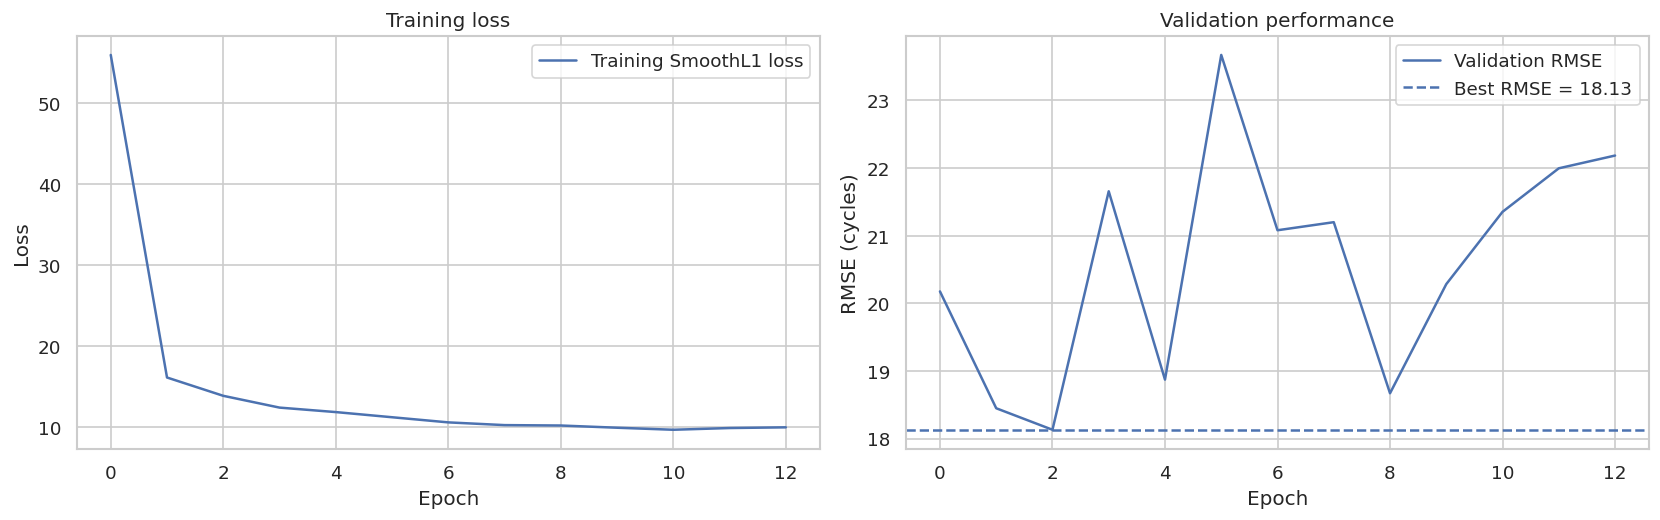

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].plot(history["train_loss"], label="Training SmoothL1 loss")
axes[0].set_title("Training loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].plot(history["val_rmse"], label="Validation RMSE")
axes[1].axhline(best_val_rmse, linestyle="--", label=f"Best RMSE = {best_val_rmse:.2f}")
axes[1].set_title("Validation performance")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("RMSE (cycles)")
axes[1].legend()
plt.tight_layout()
plt.show()

## 13. Fit classical baselines and compare on the same validation engines

For a fair engine-level comparison, we evaluate each classical model at the **last observed window** of each validation engine, and compare that with the CNN's prediction at the same engine's final observed cycle.

In [ ]:
classical_models = {
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=400, min_samples_leaf=2, max_features=0.9,
        random_state=SEED, n_jobs=-1
    ),
    "Random Forest": RandomForestRegressor(
        n_estimators=350, min_samples_leaf=2, max_features=0.9,
        random_state=SEED, n_jobs=-1
    ),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=250, learning_rate=0.06, max_leaf_nodes=15,
        l2_regularization=1.0, random_state=SEED
    )
}

# Train tabular models on many fit-engine windows.
for name, estimator in classical_models.items():
    print("Fitting", name)
    estimator.fit(X_fit_windows, y_fit_windows)

# Build last-window features for each validation engine.
X_val_final, y_val_final, val_final_ids = make_summary_dataset(
    val_scaled, val_units, FEATURES, WINDOW_SIZE
)
val_cnn_pred_all = predict_torch(model, X_val_seq)

def last_window_predictions(seq_preds, seq_units, seq_cycles, requested_units):
    pred_map = {}
    for uid in requested_units:
        mask = seq_units == uid
        if not mask.any():
            continue
        idx = np.argmax(seq_cycles[mask])
        pred_map[int(uid)] = float(seq_preds[mask][idx])
    return pred_map

val_cnn_map = last_window_predictions(
    val_cnn_pred_all, val_seq_units, val_seq_cycles, val_final_ids
)
y_val_engine = np.array([
    float(val_scaled[val_scaled.unit == uid].sort_values("cycle")["RUL"].iloc[-1])
    for uid in val_final_ids
])
cnn_val_predictions = np.array([val_cnn_map[int(uid)] for uid in val_final_ids])

validation_predictions = {"Temporal CNN": cnn_val_predictions}
for name, estimator in classical_models.items():
    validation_predictions[name] = estimator.predict(X_val_final)

def nasa_score(y_true, y_pred):
    # NASA score penalizes overestimating RUL more heavily than underestimating it.
    # d = prediction - truth; positive d means the model predicts too much life.
    d = np.asarray(y_pred) - np.asarray(y_true)
    scores = np.where(d < 0, np.exp(-d / 13.0) - 1.0, np.exp(d / 10.0) - 1.0)
    return float(np.sum(scores))

def metric_row(y_true, y_pred, name):
    y_pred = np.clip(np.asarray(y_pred), 0, RUL_CAP)
    return {
        "Model": name,
        "MAE (cycles)": mean_absolute_error(y_true, y_pred),
        "RMSE (cycles)": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
        "NASA score (lower is better)": nasa_score(y_true, y_pred)
    }

val_results = pd.DataFrame([
    metric_row(y_val_engine, pred, name)
    for name, pred in validation_predictions.items()
]).sort_values("RMSE (cycles)")

display(val_results.style.format({
    "MAE (cycles)": "{:.2f}",
    "RMSE (cycles)": "{:.2f}",
    "R2": "{:.3f}",
    "NASA score (lower is better)": "{:.1f}"
}))

Fitting Extra Trees
Fitting Random Forest
Fitting HistGradientBoosting


,Model,MAE (cycles),RMSE (cycles),R2,NASA score (lower is better)
1,Extra Trees,2.87,2.99,0.000,6.7
3,HistGradientBoosting,2.11,3.28,0.000,5.6
2,Random Forest,3.13,3.29,0.000,7.5
0,Temporal CNN,4.94,5.37,0.000,13.6


## 14. Validation plots: predicted vs actual RUL

The scatter plot shows calibration and error. The dashed diagonal is ideal: predictions on that line equal the true capped RUL.

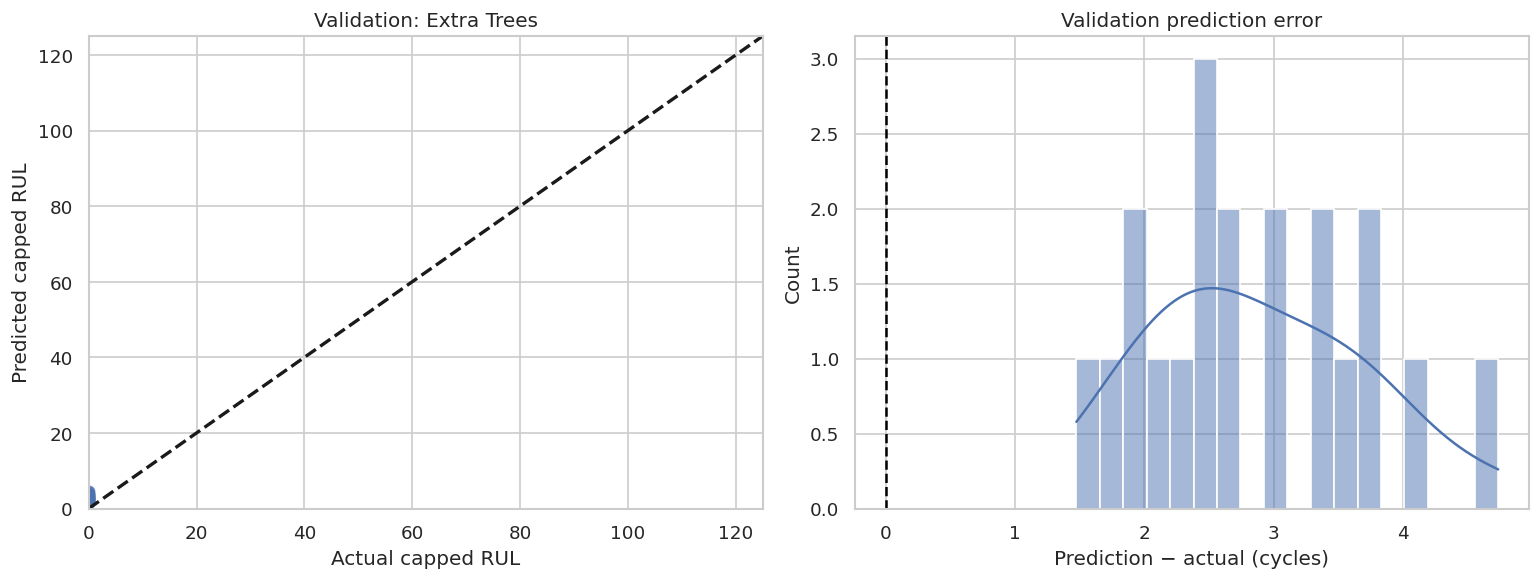

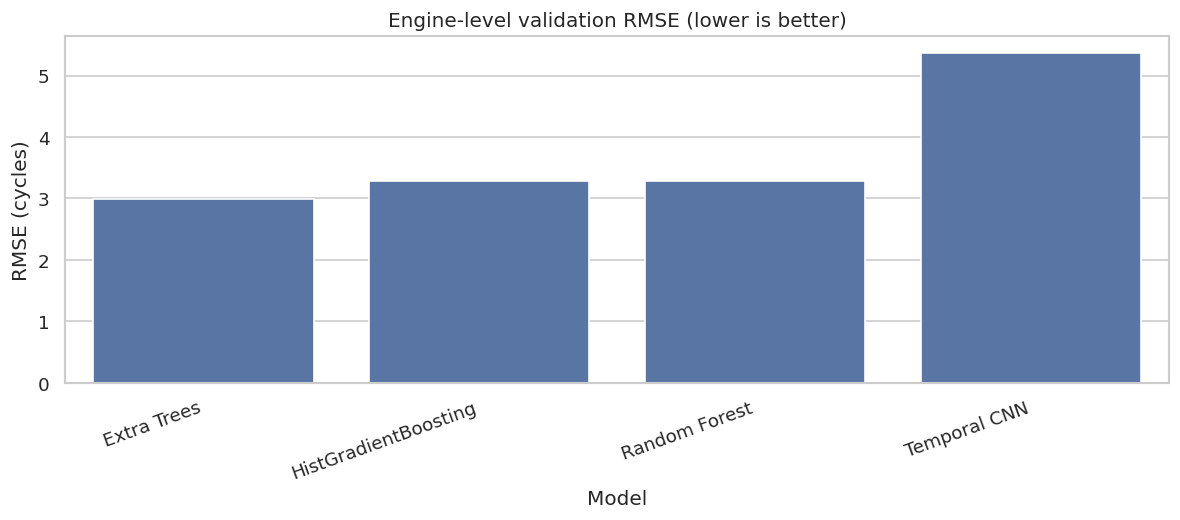

In [ ]:
best_name = val_results.iloc[0]["Model"]
best_val_pred = np.clip(validation_predictions[best_name], 0, RUL_CAP)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(y_val_engine, best_val_pred, alpha=0.8)
axes[0].plot([0, RUL_CAP], [0, RUL_CAP], "k--", linewidth=2)
axes[0].set_xlim(0, RUL_CAP)
axes[0].set_ylim(0, RUL_CAP)
axes[0].set_xlabel("Actual capped RUL")
axes[0].set_ylabel("Predicted capped RUL")
axes[0].set_title(f"Validation: {best_name}")

residuals = best_val_pred - y_val_engine
sns.histplot(residuals, bins=18, kde=True, ax=axes[1])
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_title("Validation prediction error")
axes[1].set_xlabel("Prediction − actual (cycles)")
plt.tight_layout()
plt.show()

# Compare model RMSE visually.
plt.figure(figsize=(10, 4.5))
sns.barplot(data=val_results, x="Model", y="RMSE (cycles)")
plt.xticks(rotation=20, ha="right")
plt.title("Engine-level validation RMSE (lower is better)")
plt.tight_layout()
plt.show()

## 15. Final evaluation on the official test engines

This is the final held-out evaluation. We predict RUL at the last observed cycle of each test engine and compare against the official `RUL_FDxxx.txt` values.

**Important:** The training target is capped, so the model's predictions are clipped to `[0, RUL_CAP]`. The official test RUL values are also capped for the capped-target comparison. We report metrics on that consistent target scale.

In [ ]:
test_units_sorted = np.array(sorted(test_scaled_all["unit"].unique()))
X_test_final, _, test_final_ids = make_summary_dataset(
    test_scaled_all.assign(RUL=test_scaled_all["RUL"]), test_units_sorted, FEATURES, WINDOW_SIZE
)

# Official RUL is supplied for the final observation of each test engine.
y_test_official_raw = np.array([official_rul_by_unit[int(uid)] for uid in test_final_ids], dtype=float)
y_test_official = np.clip(y_test_official_raw, 0, RUL_CAP)

test_cnn_pred_all = predict_torch(model, X_test_seq)
test_cnn_map = last_window_predictions(
    test_cnn_pred_all, test_seq_units, test_seq_cycles, test_final_ids
)
test_cnn_predictions = np.array([test_cnn_map[int(uid)] for uid in test_final_ids])

test_predictions = {"Temporal CNN": test_cnn_predictions}
for name, estimator in classical_models.items():
    test_predictions[name] = estimator.predict(X_test_final)

test_results = pd.DataFrame([
    metric_row(y_test_official, pred, name)
    for name, pred in test_predictions.items()
]).sort_values("RMSE (cycles)")

display(test_results.style.format({
    "MAE (cycles)": "{:.2f}",
    "RMSE (cycles)": "{:.2f}",
    "R2": "{:.3f}",
    "NASA score (lower is better)": "{:.1f}"
}))

,Model,MAE (cycles),RMSE (cycles),R2,NASA score (lower is better)
3,HistGradientBoosting,8.54,11.56,0.917,193.3
1,Extra Trees,8.94,11.58,0.916,189.9
2,Random Forest,8.89,11.86,0.912,200.1
0,Temporal CNN,14.38,18.88,0.778,960.6


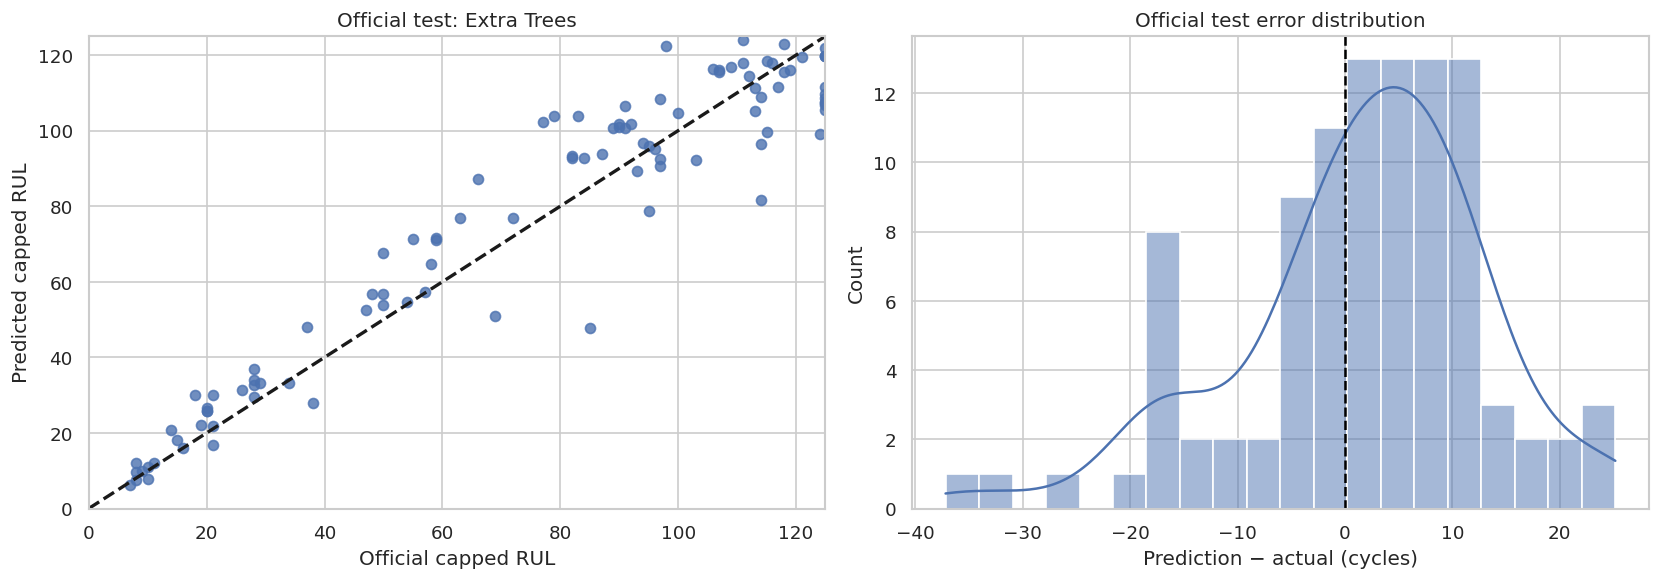

,engine_id,actual_rul_raw,actual_rul_capped,predicted_rul,error_pred_minus_actual,absolute_error
92,93,85,85,47.8,-37.2,37.2
44,45,114,114,81.7,-32.3,32.3
66,67,77,77,102.2,+25.2,25.2
11,12,124,124,99.1,-24.9,24.9
49,50,79,79,103.8,+24.8,24.8
1,2,98,98,122.3,+24.3,24.3
26,27,66,66,87.3,+21.3,21.3
14,15,83,83,103.9,+20.9,20.9
73,74,126,125,105.6,-19.4,19.4
94,95,128,125,106.9,-18.1,18.1


In [ ]:
# Plot final test predictions for the best validation-selected model.
# Selection is based on validation RMSE, not the test results.
selected_model_name = best_name
selected_test_pred = np.clip(test_predictions[selected_model_name], 0, RUL_CAP)
test_errors = selected_test_pred - y_test_official

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(y_test_official, selected_test_pred, alpha=0.8)
axes[0].plot([0, RUL_CAP], [0, RUL_CAP], "k--", linewidth=2)
axes[0].set_xlim(0, RUL_CAP)
axes[0].set_ylim(0, RUL_CAP)
axes[0].set_xlabel("Official capped RUL")
axes[0].set_ylabel("Predicted capped RUL")
axes[0].set_title(f"Official test: {selected_model_name}")

sns.histplot(test_errors, bins=20, kde=True, ax=axes[1])
axes[1].axvline(0, color="black", linestyle="--")
axes[1].set_title("Official test error distribution")
axes[1].set_xlabel("Prediction − actual (cycles)")
plt.tight_layout()
plt.show()

# Inspect the engines with the largest absolute errors.
test_report = pd.DataFrame({
    "engine_id": test_final_ids,
    "actual_rul_raw": y_test_official_raw,
    "actual_rul_capped": y_test_official,
    "predicted_rul": selected_test_pred,
    "error_pred_minus_actual": test_errors,
    "absolute_error": np.abs(test_errors)
}).sort_values("absolute_error", ascending=False)

display(test_report.head(10).style.format({
    "actual_rul_raw": "{:.0f}",
    "actual_rul_capped": "{:.0f}",
    "predicted_rul": "{:.1f}",
    "error_pred_minus_actual": "{:+.1f}",
    "absolute_error": "{:.1f}"
}))

## 16. Robustness stress test: noisy sensor measurements

A model can perform well on clean validation data and still fail when measurements become noisier. Here we add Gaussian noise to standardized sensor/setting inputs and measure how much the chosen model's error changes.

This is a **synthetic stress test**, not a claim that the noise exactly represents real aircraft sensor failures. A more complete robustness study should also test sensor dropout, operating-condition shifts, and each C-MAPSS subset separately.

,Noise std (standardized units),MAE,RMSE,NASA score
0,0.00,14.38,18.88,960.6
1,0.05,14.31,18.84,946.3
2,0.10,14.83,19.29,1044.1
3,0.20,14.51,18.95,949.3
4,0.35,15.16,19.90,707.6


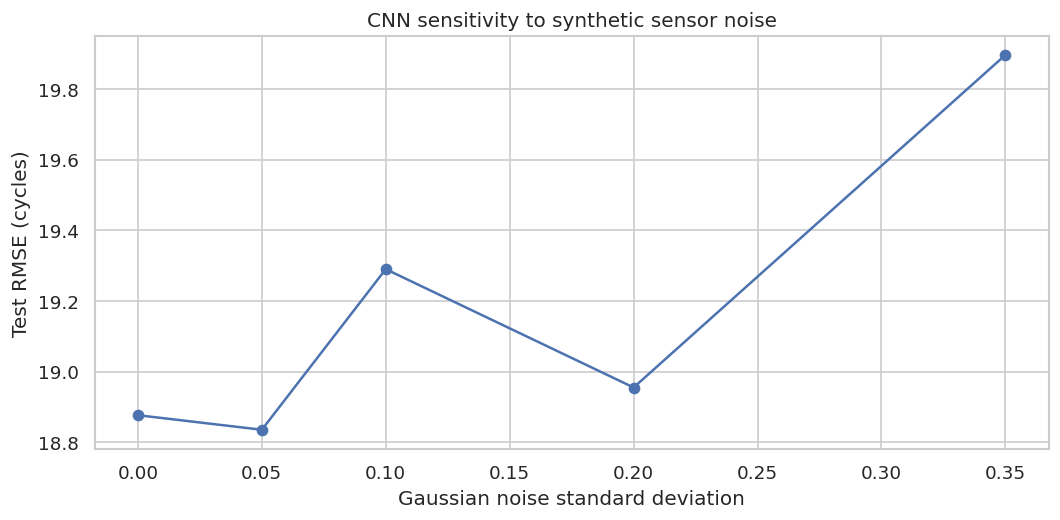

In [ ]:
def perturb_scaled_dataframe(df, feature_cols, noise_std=0.10, seed=123):
    rng = np.random.default_rng(seed)
    out = df.copy()
    out.loc[:, feature_cols] = out[feature_cols].to_numpy() + rng.normal(
        loc=0.0, scale=noise_std, size=out[feature_cols].shape
    )
    return out

noise_levels = [0.0, 0.05, 0.10, 0.20, 0.35]
robustness_rows = []

# For the CNN, perturb the final test sequences directly.
# The model is fixed: no retraining is performed during this stress test.
rng = np.random.default_rng(SEED)
for sigma in noise_levels:
    X_noisy = X_test_seq.copy()
    if sigma > 0:
        X_noisy += rng.normal(0, sigma, size=X_noisy.shape).astype(np.float32)
    pred_all = predict_torch(model, X_noisy)
    pred_map = last_window_predictions(pred_all, test_seq_units, test_seq_cycles, test_final_ids)
    pred_final = np.clip(np.array([pred_map[int(uid)] for uid in test_final_ids]), 0, RUL_CAP)
    robustness_rows.append({
        "Noise std (standardized units)": sigma,
        "MAE": mean_absolute_error(y_test_official, pred_final),
        "RMSE": np.sqrt(mean_squared_error(y_test_official, pred_final)),
        "NASA score": nasa_score(y_test_official, pred_final)
    })

robustness_df = pd.DataFrame(robustness_rows)
display(robustness_df.style.format({
    "Noise std (standardized units)": "{:.2f}",
    "MAE": "{:.2f}", "RMSE": "{:.2f}", "NASA score": "{:.1f}"
}))

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(robustness_df["Noise std (standardized units)"], robustness_df["RMSE"], marker="o")
ax.set_title("CNN sensitivity to synthetic sensor noise")
ax.set_xlabel("Gaussian noise standard deviation")
ax.set_ylabel("Test RMSE (cycles)")
plt.tight_layout()
plt.show()

## 17. Explain the model: which features matter to the tree baseline?

Tree-based feature importance is not a causal explanation, and correlated sensors can share or distort importance. Still, it is a useful diagnostic for understanding what the classical model uses.

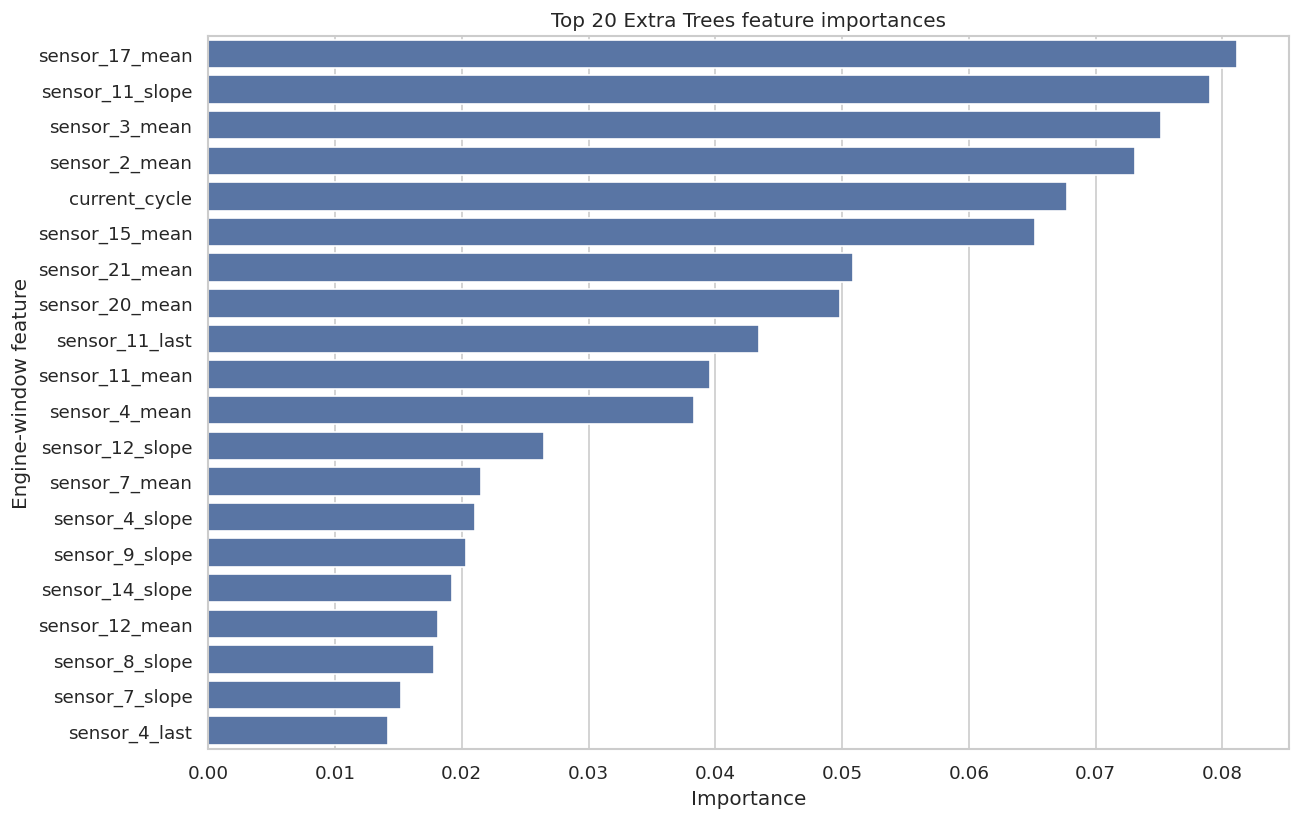

,importance
sensor_17_mean,0.081176
sensor_11_slope,0.079058
sensor_3_mean,0.075167
sensor_2_mean,0.073091
current_cycle,0.067775
sensor_15_mean,0.065251
sensor_21_mean,0.050870
sensor_20_mean,0.049850
sensor_11_last,0.043411
sensor_11_mean,0.039556


In [ ]:
importance_model = classical_models["Extra Trees"]
importance = pd.Series(
    importance_model.feature_importances_, index=X_fit_windows.columns
).sort_values(ascending=False).head(20)

plt.figure(figsize=(11, 7))
sns.barplot(x=importance.values, y=importance.index)
plt.title("Top 20 Extra Trees feature importances")
plt.xlabel("Importance")
plt.ylabel("Engine-window feature")
plt.tight_layout()
plt.show()

display(importance.to_frame("importance"))

## 18. Save the model and experiment artifacts

The following cell saves the selected validation model, preprocessing metadata, feature list, and result tables. For the CNN, the checkpoint includes the model weights and settings needed to reconstruct its architecture.

In [ ]:
ARTIFACT_DIR = Path("/content/cmapss_artifacts")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

# Save result tables and prediction report.
val_results.to_csv(ARTIFACT_DIR / "validation_results.csv", index=False)
test_results.to_csv(ARTIFACT_DIR / "test_results.csv", index=False)
test_report.to_csv(ARTIFACT_DIR / "test_engine_predictions.csv", index=False)
robustness_df.to_csv(ARTIFACT_DIR / "noise_robustness.csv", index=False)

# Save scaler and feature metadata in a portable format.
import joblib
joblib.dump(
    {"scaler": scaler, "features": FEATURES, "rul_cap": RUL_CAP,
     "window_size": WINDOW_SIZE, "subset": SUBSET},
    ARTIFACT_DIR / "preprocessing.joblib"
)

torch.save({
    "model_state_dict": model.state_dict(),
    "n_features": len(FEATURES),
    "features": FEATURES,
    "window_size": WINDOW_SIZE,
    "rul_cap": RUL_CAP,
    "subset": SUBSET,
    "seed": SEED
}, ARTIFACT_DIR / "temporal_cnn.pt")

print("Saved artifacts to:", ARTIFACT_DIR)
print("\nFiles:")
for path in sorted(ARTIFACT_DIR.iterdir()):
    print(f" - {path.name} ({path.stat().st_size / 1024:.1f} KB)")

Saved artifacts to: /content/cmapss_artifacts

Files:
 - noise_robustness.csv (0.3 KB)
 - preprocessing.joblib (1.7 KB)
 - temporal_cnn.pt (107.8 KB)
 - test_engine_predictions.csv (6.7 KB)
 - test_results.csv (0.4 KB)
 - validation_results.csv (0.4 KB)


## 19. Conclusion


### Suggested conclusion template
- **Dataset:** [FD001/FD002/FD003/FD004], with [number] training engines and [number] test engines.
- **Best validation model:** [model], selected using engine-level validation RMSE.
- **Official test result:** MAE = [value] cycles; RMSE = [value] cycles; NASA score = [value].
- **Robustness:** error [increased/decreased] as synthetic noise increased from 0.00 to 0.35 standardized units.
- **Limitation:** C-MAPSS is simulated data; results do not automatically establish real-world aircraft maintenance performance.



### Dataset reference
A. Saxena and K. Goebel (2008). *Turbofan Engine Degradation Simulation Data Set*. NASA Ames Research Center, Prognostics Center of Excellence. See the [NASA PCoE data repository](https://www.nasa.gov/intelligent-systems-division/discovery-and-systems-health/pcoe/pcoe-data-set-repository/) and [NASA DASHlink dataset page](https://c3.ndc.nasa.gov/dashlink/resources/139/).